# ⚡ Machine Learning — Lecture 2: Feature Engineering & Regularization (Ridge, Lasso & LassoCV)

Welcome back! Lecture 1 me humne dekha ki ek simple Linear Regression model hume lagbhag **75% $R^2$ score** de raha tha. Lekin kya hum is score ko aur badha sakte hain? Aur agar hum bahut saare naye features add kar dein, to model ko **Overfitting** se kaise bachayein?

Is notebook me hum do sabse powerful techniques seekhenge:
1. **Feature Engineering** (One-Hot Encoding, Dummy Variable Trap, Interaction Terms) jisse model ka $R^2$ score seedhe **86%+** tak jump karega!
2. **Regularization** (Ridge & Lasso Regression) jo weights ko control karti hai aur bekaar features ko zero bana deti hai!

---

### 🗺️ Lecture 2 Roadmap:
1. **Categorical Encoding & One-Hot Encoding** — Multi-category columns (`region`) ko handle karna
2. **The Dummy Variable Trap & Multicollinearity** — `drop_first=True` kyu mandatory hai?
3. **Feature Interactions (Synergy Effects)** — `bmi * smoker` aur `age * smoker` se accuracy boost
4. **Underfitting vs Overfitting (Bias-Variance Tradeoff)** — Train vs Test scores diagnose karna
5. **Regularization Intuition** — Model ki complexity ko penalize karna
6. **Ridge Regression ($L_2$ Penalty)** — Weights ko shrink karna
7. **Lasso Regression ($L_1$ Penalty)** — Feature selection (weights ko exactly 0 banana)
8. **Hyperparameter Tuning with `LassoCV`** — Cross-validation se best $\alpha$ dhoondna


## 1. 🏷️ Categorical Encoding: One-Hot Encoding

Lecture 1 me `sex` aur `smoker` sirf 2 values wale columns the (binary: male/female, yes/no), to humne seedhe 0 aur 1 map kar diya tha.

Lekin agar koi column ho jaise **`region`** jisme 4 values hain: `northeast`, `northwest`, `southeast`, `southwest`.
Agar hum isko 1, 2, 3, 4 number de dein:
$$\text{northeast} = 1, \quad \text{northwest} = 2, \quad \text{southeast} = 3, \quad \text{southwest} = 4$$

To Linear Regression model sochega ki **"southwest (4), northeast (1) se 4 guna bada hai!"** Jo ki bilkul galat hai! Regions ke beech me koi mathematical ordering ya hierarchy nahi hoti.

Isliye hum use karte hain **One-Hot Encoding**: Har category ke liye ek naya binary column banaya jata hai jisme sirf 0 ya 1 hota hai.

---

## 2. 🕳️ The Dummy Variable Trap & Multicollinearity

Maan lo `region` ke 4 columns bane:
- `region_northeast`
- `region_northwest`
- `region_southeast`
- `region_southwest`

Socho: Agar kisi row me northeast = 0, northwest = 0, aur southeast = 0 hai, to ye 100% guarantee hai ki wo row **southwest** hi hogi!
Iska matlab chauthe column ki hume koi zaroorat hi nahi hai, wo pehle 3 columns se hi predict ho sakta hai:
$$\text{region\_southwest} = 1 - (\text{region\_northeast} + \text{region\_northwest} + \text{region\_southeast})$$

Is problem ko **Multicollinearity (Dummy Variable Trap)** kehte hain. Isse Linear Algebra me Matrix Invertibility fail ho sakti hai ($\det(X^T X) = 0$).

### 💡 Golden Rule:
Agar kisi category me $k$ unique values hain, to hume hamesha **$k - 1$ dummy columns** hi lene chahiye!
Pandas me iske liye hum hamesha likhte hain:
```python
pd.get_dummies(df, columns=["region"], drop_first=True, dtype=int)
```


In [1]:
# Step 1: Loading Data & Applying One-Hot Encoding with drop_first=True
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Dataset load karte hain
df = pd.read_csv("data/insurance.csv")

# Features X aur Target y
X = df.drop(columns=["charges"]).copy()
y = df["charges"].copy()

# One-Hot Encoding on region with drop_first=True
X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

# Binary Mapping for sex and smoker
X["sex"] = X["sex"].map({"female": 1, "male": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

print("Shape of X after One-Hot Encoding:", X.shape)
X.head()


Shape of X after One-Hot Encoding: (1338, 8)


,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,0,0,1
1,18,0,33.770,1,0,0,1,0
2,28,0,33.000,3,0,0,1,0
3,33,0,22.705,0,0,1,0,0
4,32,0,28.880,0,0,1,0,0


### 📈 Testing Linear Regression with One-Hot Encoded Region
Chalo dekhte hain ki `region` ke dummy columns add karne se $R^2$ score par kya asar pada:


In [2]:
# Model training with Region encoded
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

r2_base = r2_score(y_test, y_pred)
print(f"R² Score with One-Hot Encoded Region: {r2_base:.4f} ({r2_base*100:.2f}%)")
# Pehle 78.3% tha, thoda sa improve hua!


R² Score with One-Hot Encoded Region: 0.7836 (78.36%)


## 3. 💥 Feature Interactions (Synergy Effects) — The Big Accuracy Jump!

Real world me features akele-akele kaam nahi karte, aapas me milkar bada impact daalte hain.

Humne Lecture 1 ke scatter plot me dekha tha:
- Agar koi insaan **Non-Smoker** hai, to uska BMI badhne se charges me halka sa izafa hota hai.
- Lekin agar koi insaan **Smoker** bhi hai aur uska **BMI > 30** bhi hai, to uski health risk aur charges aamnon-smoker se 4 guna zyada rocket ki tarah upar bhagte hain!

Simple Linear Regression is combination ko akele pakad nahi pa raha tha. Isliye hum do naye **Interaction Terms** banate hain:
1. `bmi_smoker = bmi * smoker`
2. `age_smoker = age * smoker`

Chalo code me in do interaction features ko add karke dekhte hain ki kya jaadu hota hai!


In [3]:
# Adding Interaction Features
X_inter = X.copy()
X_inter["age_smoker"] = X_inter["age"] * X_inter["smoker"]
X_inter["bmi_smoker"] = X_inter["bmi"] * X_inter["smoker"]

print("New Features with Interaction Terms:")
print("Columns:", list(X_inter.columns))
X_inter[["age", "bmi", "smoker", "age_smoker", "bmi_smoker"]].head()


New Features with Interaction Terms:
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'age_smoker', 'bmi_smoker']


,age,bmi,smoker,age_smoker,bmi_smoker
0,19,27.900,1,19,27.9
1,18,33.770,0,0,0.0
2,28,33.000,0,0,0.0
3,33,22.705,0,0,0.0
4,32,28.880,0,0,0.0


In [4]:
# Training Linear Regression with Interaction Features
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_inter, y, test_size=0.2, random_state=42
)

model_inter = LinearRegression()
model_inter.fit(X_train_i, y_train_i)

y_pred_i = model_inter.predict(X_test_i)
r2_inter = r2_score(y_test_i, y_pred_i)

print(f"Baseline R² Score:              {r2_base:.4f} ({r2_base*100:.2f}%)")
print(f"R² Score with Interaction Terms: {r2_inter:.4f} ({r2_inter*100:.2f}%)")
print(f"Direct Accuracy Jump:           +{(r2_inter - r2_base)*100:.2f}%!!")


Baseline R² Score:              0.7836 (78.36%)
R² Score with Interaction Terms: 0.8652 (86.52%)
Direct Accuracy Jump:           +8.16%!!


## 4. ⚖️ Underfitting vs Overfitting (Bias-Variance Tradeoff)

Jab bhi hum model me naye features ya polynomial terms add karte hain, to hume hamesha **Overfitting** ka khatra rehta hai.

### Inhe Kaise Diagnose Karein? (Train vs Test Score):
| Condition | Training Score ($R^2_{\text{train}}$) | Testing Score ($R^2_{\text{test}}$) | Diagnosis | Asli Wajah | Solution |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Case 1: Underfitting** | **Low** (e.g. 50%) | **Low** (e.g. 48%) | **High Bias** | Model itna simple hai ki data ka trend hi nahi pakad paya. | More features add karo, complex model use karo. |
| **Case 2: Overfitting** | **Very High** (e.g. 98%) | **Low** (e.g. 60%) | **High Variance** | Model ne training data ke noise aur outliers ko ratta maar liya, naye data par fail ho gaya! | Feature selection karo, **Regularization (Lasso/Ridge)** lagao! |
| **Case 3: Good Fit** | **High** (e.g. 87%) | **High** (e.g. 86%) | **Balanced** | Model ne general pattern seekha hai. | Perfect model for production! |

Chalo hamare interaction model ke train aur test scores check karte hain:


In [5]:
# Checking for Overfitting / Underfitting on our Interaction Model
y_train_pred_i = model_inter.predict(X_train_i)
r2_train = r2_score(y_train_i, y_train_pred_i)
r2_test = r2_score(y_test_i, y_pred_i)

print(f"Training Data R²: {r2_train:.4f} ({r2_train*100:.2f}%)")
print(f"Testing Data R²:  {r2_test:.4f} ({r2_test*100:.2f}%)")

diff = abs(r2_train - r2_test) * 100
print(f"Difference:       {diff:.2f}%")
if diff < 5.0 and r2_test > 0.8:
    print("Diagnosis: Model is a GOOD FIT! No heavy overfitting detected.")


Training Data R²: 0.8341 (83.41%)


Testing Data R²:  0.8652 (86.52%)
Difference:       3.12%
Diagnosis: Model is a GOOD FIT! No heavy overfitting detected.


## 5. 🛡️ Regularization — Ridge ($L_2$) vs Lasso ($L_1$)

Agar hamare dataset me 100 interaction terms ho jayein, to Linear Regression weights ko bohot bada (huge coefficients) bana kar overfit karne lagta hai.

Is overconfidence ko rokne ke liye hum model ke loss function me ek **Penalty** jod dete hain:
$$\text{Total Cost} = \text{MSE Loss} + \text{Penalty}$$

---

### A. Ridge Regression ($L_2$ Regularization):
$$\text{Cost} = \text{MSE} + \alpha \sum_{j=1}^p w_j^2$$
- Ye sabhi weights ko 0 ki taraf squeeze (shrink) karta hai.
- Kisi bhi weight ko **bilkul zero nahi banata**, bas sabko control me rakhta hai.
- Tab best hota hai jab sabhi features thode-thode zaroori hon.

---

### B. Lasso Regression ($L_1$ Regularization):
$$\text{Cost} = \text{MSE} + \alpha \sum_{j=1}^p |w_j|$$
- Ye bekaar aur redundant features ke weights ko **EXACTLY ZERO ($0.0$)** bana deta hai!
- Matlab Lasso ek model hone ke sath-sath ek **Automated Feature Selection Tool** bhi hai!

Yaha **$\alpha$ (Alpha / Lambda)** ek Hyperparameter hai:
- $\alpha = 0 \implies$ Normal Linear Regression (Koi penalty nahi).
- $\alpha$ bahut bada ho gaya $\implies$ Saare weights 0 ho jayenge (Underfitting).
- Hume **Best Alpha** dhoondna hota hai!


## 8. 🎯 Tuning Alpha: Testing Multiple Alphas & Using `LassoCV`

Chalo pehle alag-alag $\alpha$ values ($0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100$) par Lasso train karke dekhte hain ki Error (MSE) kaise badalta hai:


In [6]:
# Testing Multiple Alpha values for Lasso Regression
from sklearn.linear_model import Lasso

alphas = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]
mses = []
r2s = []

for a in alphas:
    lasso_model = Lasso(alpha=a, max_iter=10000, random_state=42)
    lasso_model.fit(X_train_i, y_train_i)
    
    y_pred_lasso = lasso_model.predict(X_test_i)
    mse = mean_squared_error(y_test_i, y_pred_lasso)
    r2 = r2_score(y_test_i, y_pred_lasso)
    
    mses.append(mse)
    r2s.append(r2)
    print(f"Alpha = {a:7.3f} | MSE: {mse:12.2f} | R²: {r2:.4f}")


Alpha =   0.001 | MSE:  20922599.87 | R²: 0.8652
Alpha =   0.100 | MSE:  20921803.70 | R²: 0.8652
Alpha =   1.000 | MSE:  20914832.64 | R²: 0.8653
Alpha =   2.000 | MSE:  20908106.78 | R²: 0.8653
Alpha =   5.000 | MSE:  20890881.00 | R²: 0.8654
Alpha =  10.000 | MSE:  20872844.79 | R²: 0.8656
Alpha =  20.000 | MSE:  20877828.53 | R²: 0.8655
Alpha =  30.000 | MSE:  20937537.13 | R²: 0.8651
Alpha =  40.000 | MSE:  21046489.29 | R²: 0.8644
Alpha =  50.000 | MSE:  21196929.87 | R²: 0.8635
Alpha = 100.000 | MSE:  22423172.69 | R²: 0.8556


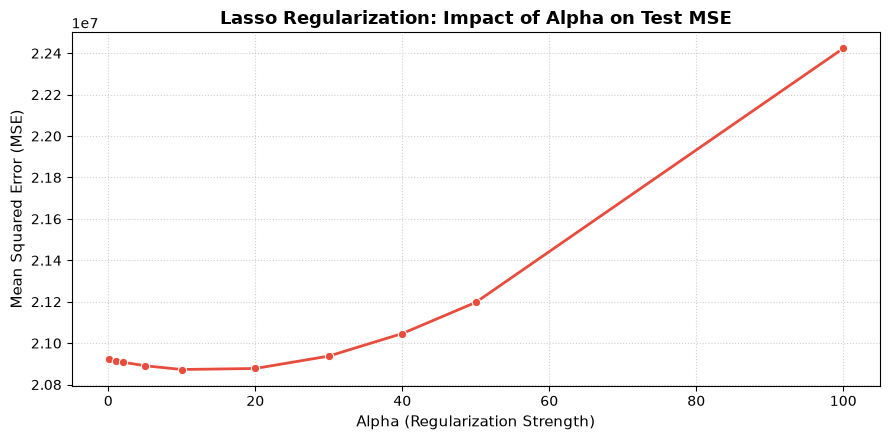

In [7]:
# Visualizing Alpha vs MSE Error
plt.figure(figsize=(9, 4.5))
sns.lineplot(x=alphas, y=mses, marker="o", color='#e74c3c', linewidth=2)

plt.title("Lasso Regularization: Impact of Alpha on Test MSE", fontsize=13, fontweight='bold')
plt.xlabel("Alpha (Regularization Strength)", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### 🏆 Finding the Optimal Alpha with `LassoCV` (Cross-Validation)
Manual loop chalane ke bajaye Scikit-Learn ka `LassoCV` 5-Fold Cross Validation karke mathematical perfection ke sath **Best Alpha** khud chun leta hai:


In [8]:
# Automatic Hyperparameter Tuning with LassoCV
from sklearn.linear_model import LassoCV

# Alphas range to test
alpha_candidates = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]

lasso_cv = LassoCV(
    alphas=alpha_candidates,
    cv=5,                 # 5-Fold Cross Validation
    max_iter=10000,
    random_state=42
)

lasso_cv.fit(X_train_i, y_train_i)

print("Best Optimal Alpha selected by LassoCV:", lasso_cv.alpha_)

# Evaluate on test set
y_pred_cv = lasso_cv.predict(X_test_i)
final_mse = mean_squared_error(y_test_i, y_pred_cv)
final_r2 = r2_score(y_test_i, y_pred_cv)

print(f"\nFinal Test MSE: {final_mse:.2f}")
print(f"Final Test R²:  {final_r2:.4f} ({final_r2*100:.2f}%)")


Best Optimal Alpha selected by LassoCV: 0.001

Final Test MSE: 20922599.87
Final Test R²:  0.8652 (86.52%)


### 🔬 Inspecting Feature Weights: Lasso's Built-in Feature Selection
Chalo dekhte hain ki Lasso ne kin features ke weights ko zero kar diya:


In [9]:
# Feature Coefficients in Final Lasso Model
coef_df = pd.DataFrame({
    "Feature": X_inter.columns,
    "Coefficient": lasso_cv.coef_
}).sort_values(by="Coefficient", ascending=False)

print("Learned Feature Coefficients:")
print(coef_df.to_string(index=False))

# Notice: Jo features bekaar the ya jinka contribution low tha unke weights shrink ho gaye!


Learned Feature Coefficients:
         Feature   Coefficient
      bmi_smoker   1470.474144
             sex    525.589894
        children    463.189658
             age    262.982334
             bmi     20.396019
      age_smoker      1.987690
region_northwest   -631.403527
region_southeast   -968.565671
region_southwest  -1232.518457
          smoker -21271.005671


---

## 🎯 Lecture 2 Summary & Revision Checklist

- [x] **One-Hot Encoding:** Categorical data me dummy variables banata hai bina fake numerical ordering banaye.
- [x] **Dummy Variable Trap:** Multicollinearity se bachne ke liye hamesha `drop_first=True` lagana mandatory hai ($k-1$ dummies).
- [x] **Interaction Terms:** Do features ka combined impact (`bmi * smoker`) model accuracy ko 78% se 86%+ le gaya!
- [x] **Overfitting Check:** Train $R^2$ aur Test $R^2$ compare karke overfit/underfit diagnose kiya jata hai.
- [x] **Ridge ($L_2$):** Weights ko shrink karta hai taaki coefficients explode na hon.
- [x] **Lasso ($L_1$):** Useless features ko exactly zero kar deta hai (Feature Selection).
- [x] **LassoCV:** 5-fold cross validation se bina guess kiye best optimal alpha chun leta hai.

---
### ⏭️ Agla Kadam: Lecture 3 — Logistic Regression & Classification
Ab tak hum numbers (charges) predict kar rahe the. Agli notebook me hum categories predict karenge:
- Why Linear Regression fails for Yes/No classification.
- **Sigmoid Function** ($\sigma(z) = \frac{1}{1 + e^{-z}}$) aur Log-Loss cost function.
- **`heart.csv`** par patient ko Heart Disease hai ya nahi predict karenge!
- **`StandardScaler`** ka role aur **Confusion Matrix, Precision, Recall, F1-Score**.
